In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import torch
import pandas as pd

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory:", round(
        torch.cuda.get_device_properties(0).total_memory / 1024**3, 2
    ), "GB")
else:
    print("No GPU detected. Enable GPU in Colab settings.")

PyTorch version: 2.14.1+cpu
CUDA available: False
No GPU detected. Enable GPU in Colab settings.


In [3]:
!pip install -U ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 7.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [ultralytics]


In [4]:
import ultralytics

print("Ultralytics version:", ultralytics.__version__)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics version: 8.4.216


In [5]:
from pathlib import Path

processed_path = Path("/content/drive/MyDrive/PPE/processed")
yaml_output_path = processed_path / "data.yaml"

In [6]:
training_config = {
    "data": str(yaml_output_path),
    "imgsz": 640,
    "epochs": 50,
    "batch": 16,
    "patience": 10,
    "workers": 2,
    "seed": 42,
    "device": 0,
    "plots": True,
    "save": True,
    "verbose": True
}

print(training_config)

{'data': '/content/drive/MyDrive/PPE/processed/data.yaml', 'imgsz': 640, 'epochs': 50, 'batch': 16, 'patience': 10, 'workers': 2, 'seed': 42, 'device': 0, 'plots': True, 'save': True, 'verbose': True}


In [7]:
from ultralytics import YOLO

model_checkpoints = {
    "YOLOv8n": "yolov8n.pt",
    "YOLO11": "yolo11n.pt",
     "YOLO26": "yolo26n.pt"
}

for model_name, checkpoint in model_checkpoints.items():
  model = YOLO(checkpoint)
  print(f"{model_name}: loaded successfully")

  del model

YOLOv8n: loaded successfully
YOLO11: loaded successfully
YOLO26: loaded successfully


In [ ]:
"""
# Load pretrained YOLOv8 Nano
model_yolov8 = YOLO("yolov8n.pt")

# Train on our PPE dataset
results_yolov8 = model_yolov8.train(
    **training_config,
    project="/content/drive/MyDrive/PPE/runs",
    name="yolov8n_ppe",
    exist_ok=True
)

"""

'\n# Load pretrained YOLOv8 Nano\nmodel_yolov8 = YOLO("yolov8n.pt")\n\n# Train on our PPE dataset\nresults_yolov8 = model_yolov8.train(\n    **training_config,\n    project="/content/drive/MyDrive/PPE/runs",\n    name="yolov8n_ppe",\n    exist_ok=True\n)\n\n'

In [ ]:
"""
from pathlib import Path

best_model_path = Path(
    "/content/drive/MyDrive/PPE/runs/yolov8n_ppe/weights/best.pt"
)

print("Model exists:", best_model_path.exists())
print("Model size:", round(best_model_path.stat().st_size / (1024**2), 2), "MB")
"""

'\nfrom pathlib import Path\n\nbest_model_path = Path(\n    "/content/drive/MyDrive/PPE/runs/yolov8n_ppe/weights/best.pt"\n)\n\nprint("Model exists:", best_model_path.exists())\nprint("Model size:", round(best_model_path.stat().st_size / (1024**2), 2), "MB")\n'

In [8]:
results_path = Path(
    "/content/drive/MyDrive/PPE/runs/yolov8n_ppe/results.csv"
)

print("Results exists:", results_path.exists())

results_df = pd.read_csv(results_path)

print("Number of epochs:", len(results_df))
print("\nAvailable metrics:")
print(results_df.columns.tolist())

results_df.head()

Results exists: True
Number of epochs: 50

Available metrics:
['epoch', 'time', 'train/box_loss', 'train/cls_loss', 'train/dfl_loss', 'metrics/precision(B)', 'metrics/recall(B)', 'metrics/mAP50(B)', 'metrics/mAP50-95(B)', 'val/box_loss', 'val/cls_loss', 'val/dfl_loss', 'lr/pg0', 'lr/pg1', 'lr/pg2']


,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
0,1,63.9937,1.49783,2.05502,1.37650,0.60383,0.42988,0.44825,0.23021,1.63202,1.51534,1.36573,0.000301,0.000301,0.000301
1,2,123.8310,1.51270,1.37680,1.35461,0.64245,0.47797,0.50188,0.25698,1.65768,1.42731,1.36669,0.000592,0.000592,0.000592
2,3,184.8020,1.52346,1.32160,1.35108,0.68458,0.46859,0.50481,0.26300,1.65202,1.42738,1.39689,0.000871,0.000871,0.000871
3,4,245.3300,1.52455,1.28480,1.35151,0.69524,0.49376,0.52894,0.26921,1.65896,1.34100,1.37987,0.000855,0.000855,0.000855
4,5,305.7660,1.50159,1.24034,1.32989,0.71003,0.48894,0.53963,0.28671,1.62900,1.31883,1.32896,0.000837,0.000837,0.000837


In [9]:
# Find the epoch with the highest validation mAP50-95
best_epoch_idx = results_df["metrics/mAP50-95(B)"].idxmax()

best_epoch = results_df.loc[best_epoch_idx]
last_epoch = results_df.iloc[-1]

print("BEST EPOCH")
print(best_epoch[[
    "epoch",
    "train/box_loss",
    "train/cls_loss",
    "train/dfl_loss",
    "val/box_loss",
    "val/cls_loss",
    "val/dfl_loss",
    "metrics/precision(B)",
    "metrics/recall(B)",
    "metrics/mAP50(B)",
    "metrics/mAP50-95(B)"
]])

print("\nFINAL EPOCH")
print(last_epoch[[
    "epoch",
    "metrics/precision(B)",
    "metrics/recall(B)",
    "metrics/mAP50(B)",
    "metrics/mAP50-95(B)"
]])

BEST EPOCH
epoch                   48.00000
train/box_loss           1.09260
train/cls_loss           0.62757
train/dfl_loss           1.07647
val/box_loss             1.44791
val/cls_loss             0.84212
val/dfl_loss             1.20623
metrics/precision(B)     0.82394
metrics/recall(B)        0.61152
metrics/mAP50(B)         0.67266
metrics/mAP50-95(B)      0.39039
Name: 47, dtype: float64

FINAL EPOCH
epoch                   50.00000
metrics/precision(B)     0.84316
metrics/recall(B)        0.60582
metrics/mAP50(B)         0.67231
metrics/mAP50-95(B)      0.38991
Name: 49, dtype: float64


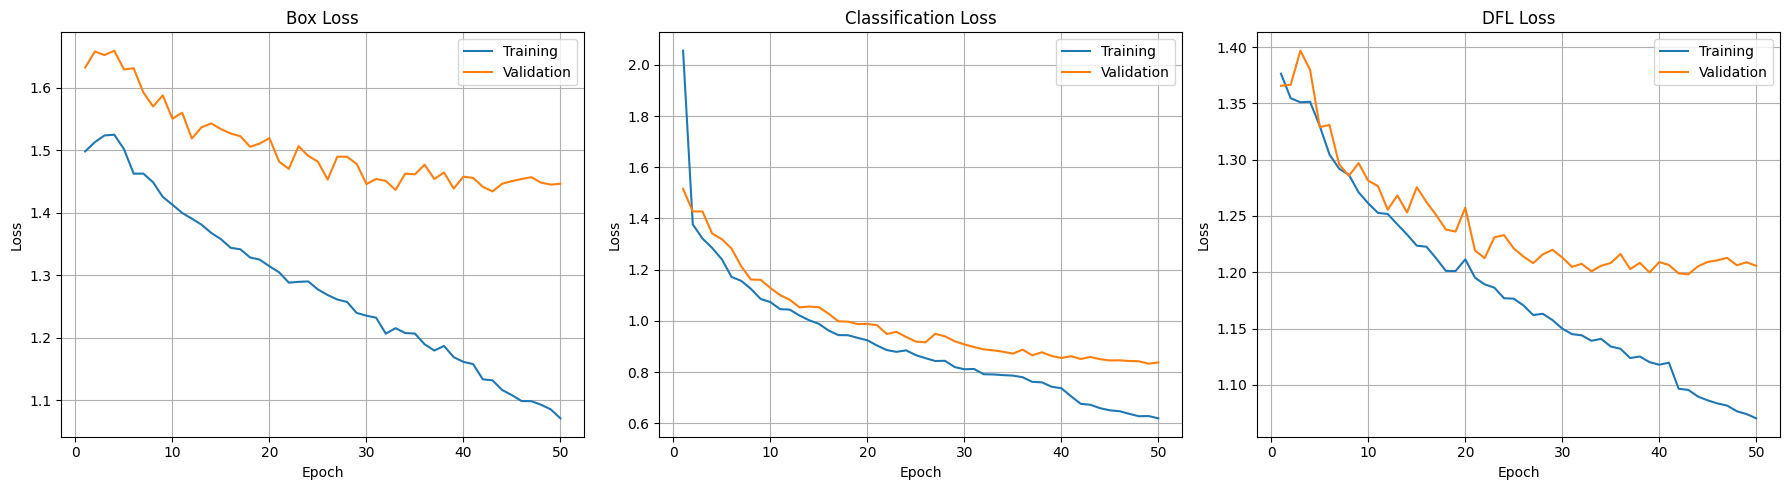

In [10]:
import matplotlib.pyplot as plt

loss_pairs = [
    ("train/box_loss", "val/box_loss", "Box Loss"),
    ("train/cls_loss", "val/cls_loss", "Classification Loss"),
    ("train/dfl_loss", "val/dfl_loss", "DFL Loss")
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (train_col, val_col, title) in zip(axes, loss_pairs):

    ax.plot(results_df["epoch"], results_df[train_col], label="Training")
    ax.plot(results_df["epoch"], results_df[val_col], label="Validation")

    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()

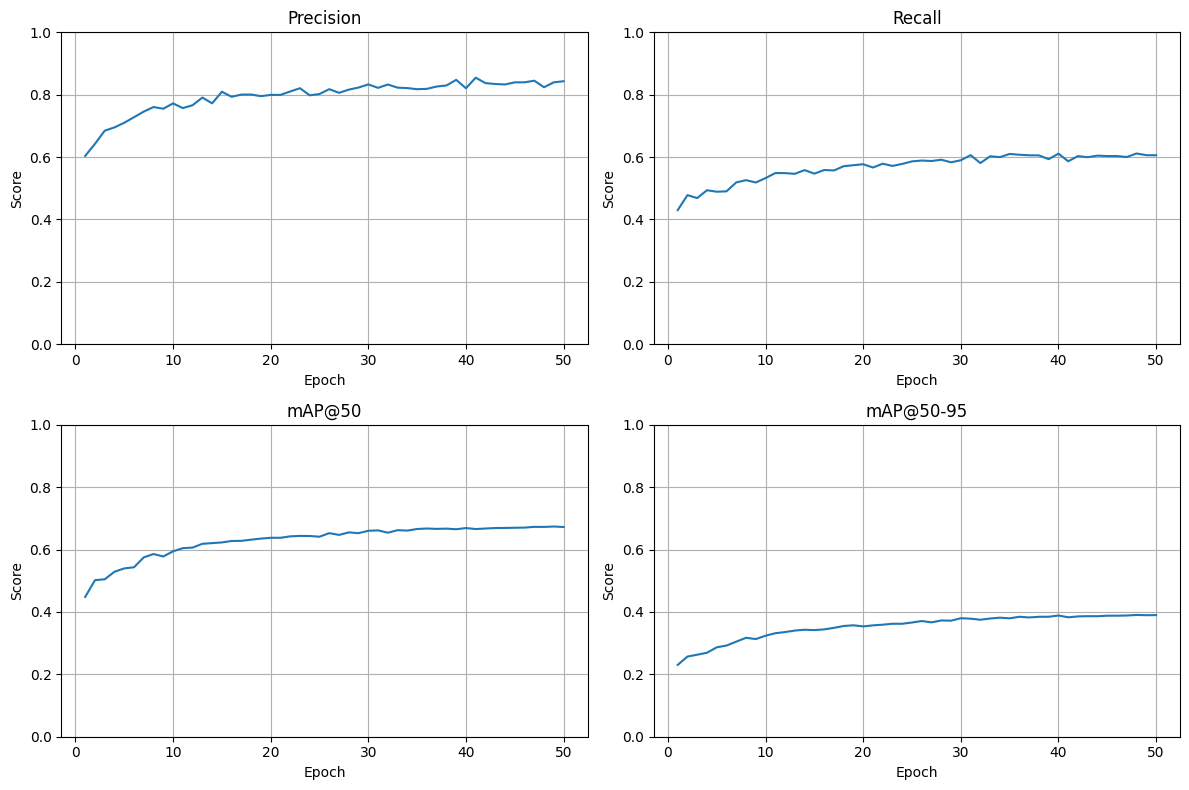

In [ ]:
metric_columns = [
    ("metrics/precision(B)", "Precision"),
    ("metrics/recall(B)", "Recall"),
    ("metrics/mAP50(B)", "mAP@50"),
    ("metrics/mAP50-95(B)", "mAP@50-95")
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, (column, title) in zip(axes.flat, metric_columns):

    ax.plot(results_df["epoch"], results_df[column])

    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Score")
    ax.set_ylim(0, 1)
    ax.grid(True)

plt.tight_layout()
plt.show()

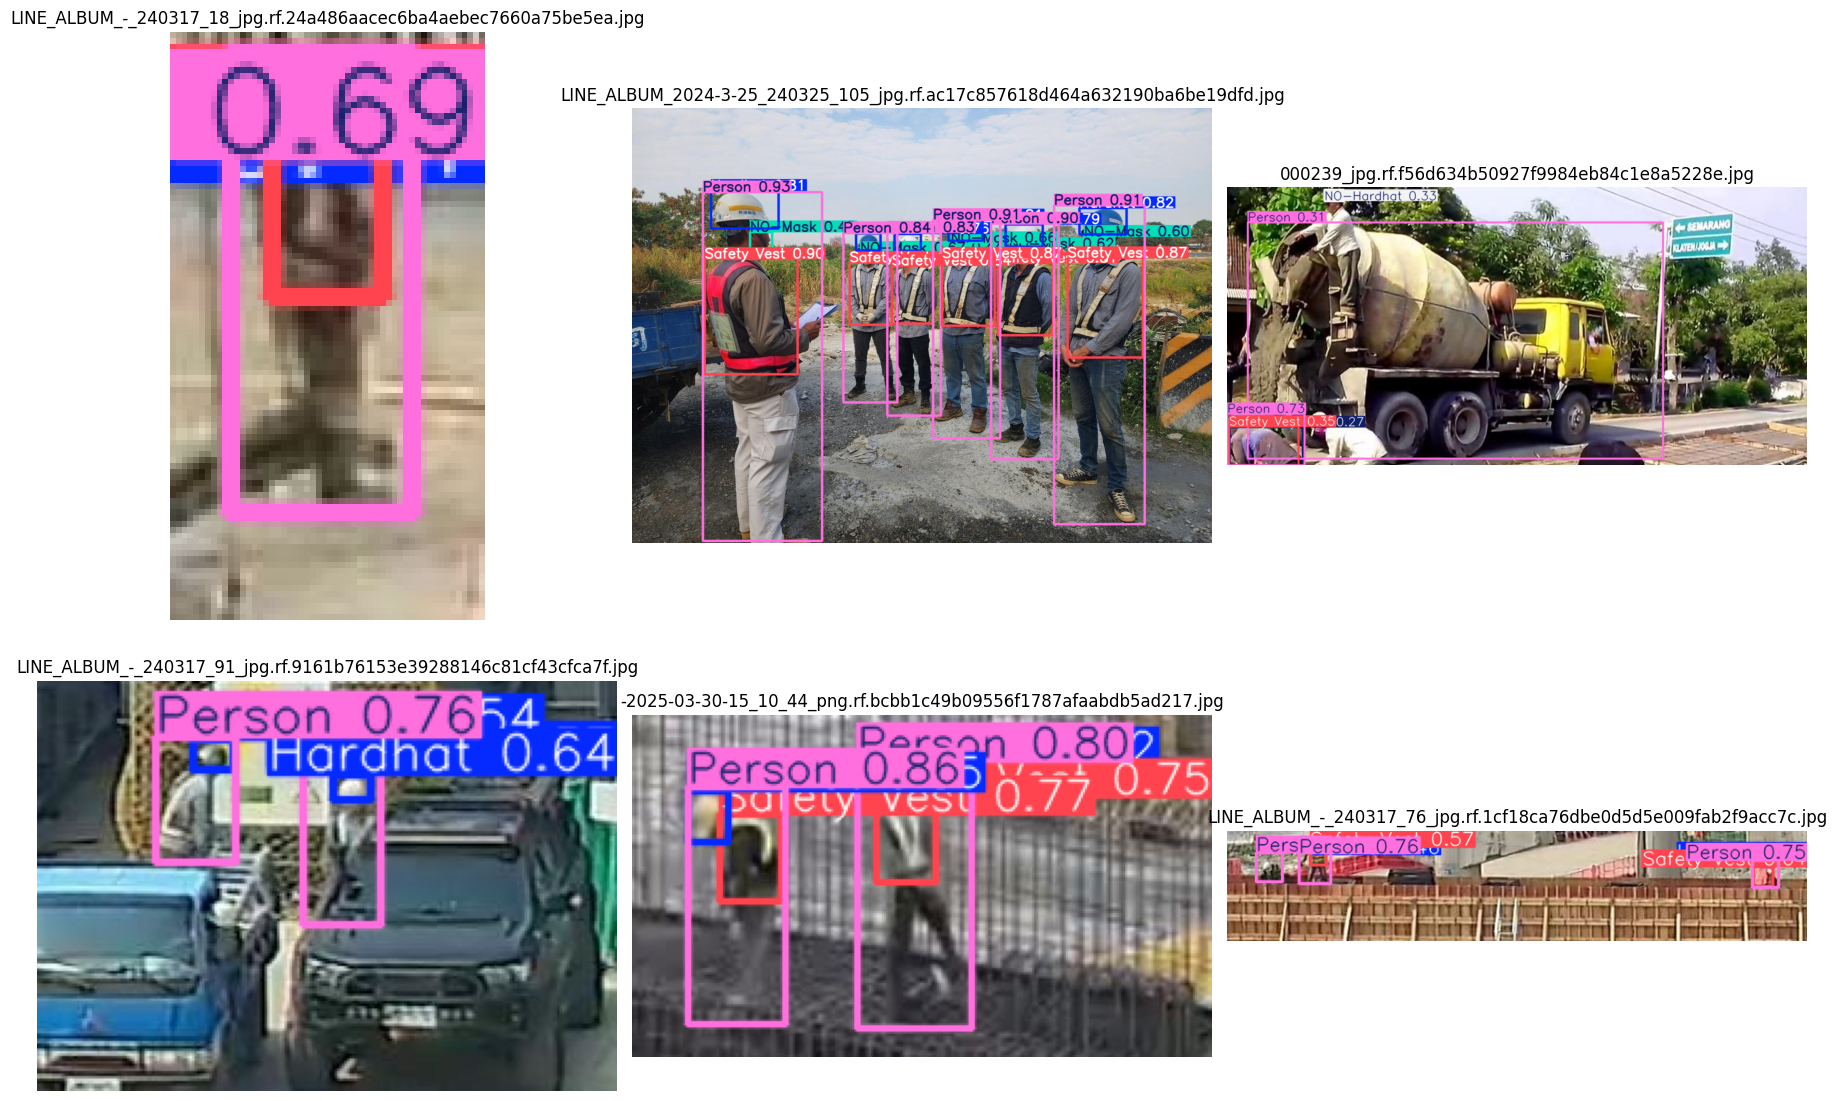

In [ ]:
import random
import matplotlib.pyplot as plt
from ultralytics import YOLO

# Load the best trained checkpoint
model_yolov8 = YOLO(
    "/content/drive/MyDrive/PPE/runs/yolov8n_ppe/weights/best.pt"
)

# Select six random validation images
validation_images = list(
    (processed_path / "valid" / "images").glob("*")
)

sample_images = random.sample(validation_images, 6)

# Run predictions
predictions = model_yolov8.predict(
    source=[str(image) for image in sample_images],
    imgsz=640,
    conf=0.25,
    device=0,
    verbose=False
)

# Display predictions
fig, axes = plt.subplots(2, 3, figsize=(18, 12))

for ax, result in zip(axes.flat, predictions):
    annotated_image = result.plot()
    annotated_image = annotated_image[:, :, ::-1]

    ax.imshow(annotated_image)
    ax.set_title(result.path.split("/")[-1])
    ax.axis("off")

plt.tight_layout()
plt.show()

# YOLOv8 Nano — Training and Evaluation Report

## 1. Model Configuration

| Parameter | Configuration |
|---|---|
| Architecture | YOLOv8 |
| Model variant | Nano |
| Pretrained checkpoint | yolov8n.pt |
| Image size | 640 × 640 |
| Epochs | 50 |
| Batch size | 16 |
| Optimizer | Auto |
| Early stopping patience | 10 |
| Random seed | 42 |
| Hardware | NVIDIA Tesla T4 |
| Dataset classes | 7 |

The model was fine-tuned using pretrained weights on the prepared PPE dataset.

## 2. Dataset

| Split | Images |
|---|---:|
| Training | 2,996 |
| Validation | 641 |
| Testing | 643 |
| Total | 4,280 |

Target classes:
- Hardhat
- Mask
- NO-Hardhat
- NO-Mask
- NO-Safety Vest
- Person
- Safety Vest

## 3. Training Results

- Total epochs completed: 50
- Training duration: approximately 0.847 hours
- Best validation checkpoint: best.pt
- Final checkpoint: last.pt

The best validation checkpoint was obtained at epoch 48.

## 4. Validation Performance

| Metric | Best validation result |
|---|---:|
| Precision | 0.8239 |
| Recall | 0.6115 |
| mAP@50 | 0.6727 |
| mAP@50–95 | 0.3904 |

## 5. Training Behaviour

The training losses decreased consistently throughout the experiment.

Validation losses initially decreased but gradually plateaued, while the gap between training and validation losses widened.

This suggests a generalization gap and possible mild overfitting.

The validation metrics also showed diminishing improvements during the later training epochs.

## 6. Visual Prediction Analysis

Six randomly selected validation images were used for qualitative inspection.

Observations:
- The model successfully identified several people and PPE-related objects.
- Some predictions overlapped.
- Some PPE classes appeared to be detected in unrelated image regions.
- Small and distant objects presented detection challenges.
- Performance varied across different scene types.

These observations indicate that aggregate metrics alone are insufficient to establish the reliability of the detector.

## 7. Strengths

- Successfully fine-tuned pretrained weights.
- Achieved relatively strong precision.
- Detected multiple PPE-related classes.
- Training and validation losses showed initial learning progress.
- Model checkpoint and experiment results were saved successfully.

## 8. Limitations

- Recall remained relatively low at approximately 61%.
- mAP@50–95 indicated room for improvement in localization.
- Some visual predictions appeared unreliable.
- Validation performance plateaued during later epochs.
- Class-specific weaknesses require further investigation.

## 9. Conclusion

YOLOv8 Nano established the baseline for the PPE detection experiment.

The model demonstrated the ability to detect several PPE-related objects, but its recall, localization performance and visual prediction reliability leave room for improvement.

The trained checkpoint is retained for future inference and comparison.

The next experiment will evaluate YOLO11 Nano using the same dataset splits and experimental configuration.

# YOLO11 Nano — Experimentation

## Objective
Train and evaluate YOLO11 Nano for PPE detection using the prepared construction hazard dataset.

## Model Configuration
- Architecture: YOLO11
- Variant: Nano (`yolo11n.pt`)
- Image size: 640 × 640
- Epochs: 50
- Batch size: 16
- Optimizer: Auto
- Early stopping patience: 10
- Random seed: 42
- Device: NVIDIA Tesla T4

## Experimental Approach
Fine-tune the pretrained YOLO11 Nano checkpoint using the same training, validation and test splits used for YOLOv8.

Evaluate its performance using:
- Precision
- Recall
- mAP@50
- mAP@50–95
- Training and validation losses
- Visual prediction inspection

## Expected Outcome
Establish YOLO11 Nano's detection performance and compare it against the YOLOv8 baseline under consistent experimental conditions.

In [ ]:
"""
# Load pretrained YOLO11 Nano
model_yolo11 = YOLO("yolo11n.pt")

# Train YOLO11 on the PPE dataset
results_yolo11 = model_yolo11.train(
    **training_config,
    project="/content/drive/MyDrive/PPE/runs",
    name="yolo11n_ppe",
    exist_ok=True
)
"""

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/PPE/processed/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo11n_ppe, nbs=64, nms=None, opset=None,

In [ ]:
from pathlib import Path
import pandas as pd

results_path_yolo11 = Path(
    "/content/drive/MyDrive/PPE/runs/yolo11n_ppe/results.csv"
)

results_df_yolo11 = pd.read_csv(results_path_yolo11)

print("Epochs:", len(results_df_yolo11))
print("Available metrics:")
print(results_df_yolo11.columns.tolist())

Epochs: 50
Available metrics:
['epoch', 'time', 'train/box_loss', 'train/cls_loss', 'train/dfl_loss', 'metrics/precision(B)', 'metrics/recall(B)', 'metrics/mAP50(B)', 'metrics/mAP50-95(B)', 'val/box_loss', 'val/cls_loss', 'val/dfl_loss', 'lr/pg0', 'lr/pg1', 'lr/pg2']


In [ ]:
best_epoch_idx = results_df_yolo11[
    "metrics/mAP50-95(B)"
].idxmax()

best_epoch = results_df_yolo11.loc[best_epoch_idx]
last_epoch = results_df_yolo11.iloc[-1]

metrics = [
    "epoch",
    "train/box_loss",
    "train/cls_loss",
    "train/dfl_loss",
    "val/box_loss",
    "val/cls_loss",
    "val/dfl_loss",
    "metrics/precision(B)",
    "metrics/recall(B)",
    "metrics/mAP50(B)",
    "metrics/mAP50-95(B)"
]

print("BEST EPOCH")
print(best_epoch[metrics])

print("\nFINAL EPOCH")
print(last_epoch[metrics])

BEST EPOCH
epoch                   50.00000
train/box_loss           1.08990
train/cls_loss           0.63078
train/dfl_loss           1.06456
val/box_loss             1.42873
val/cls_loss             0.84182
val/dfl_loss             1.17561
metrics/precision(B)     0.83792
metrics/recall(B)        0.60852
metrics/mAP50(B)         0.67178
metrics/mAP50-95(B)      0.38957
Name: 49, dtype: float64

FINAL EPOCH
epoch                   50.00000
train/box_loss           1.08990
train/cls_loss           0.63078
train/dfl_loss           1.06456
val/box_loss             1.42873
val/cls_loss             0.84182
val/dfl_loss             1.17561
metrics/precision(B)     0.83792
metrics/recall(B)        0.60852
metrics/mAP50(B)         0.67178
metrics/mAP50-95(B)      0.38957
Name: 49, dtype: float64


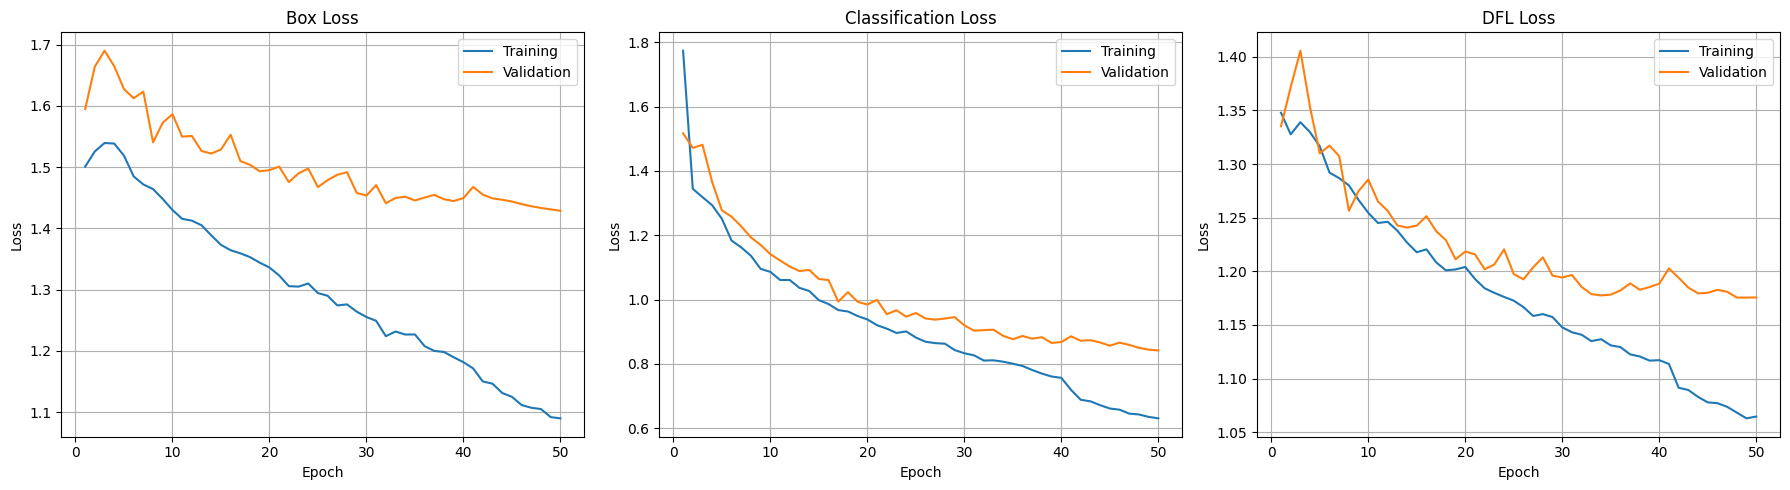

In [ ]:
import matplotlib.pyplot as plt

loss_pairs = [
    ("train/box_loss", "val/box_loss", "Box Loss"),
    ("train/cls_loss", "val/cls_loss", "Classification Loss"),
    ("train/dfl_loss", "val/dfl_loss", "DFL Loss")
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (train_col, val_col, title) in zip(axes, loss_pairs):

    ax.plot(results_df_yolo11["epoch"], results_df_yolo11[train_col], label="Training")
    ax.plot(results_df_yolo11["epoch"], results_df_yolo11[val_col], label="Validation")

    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()

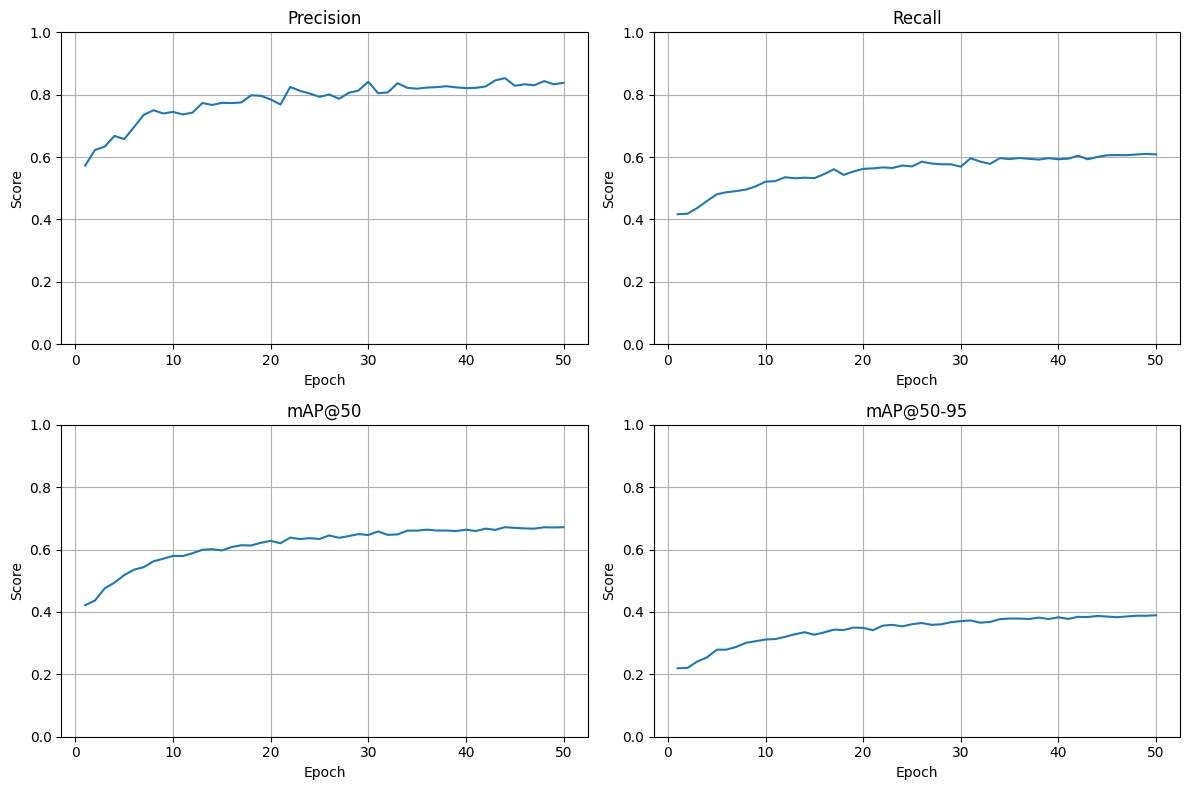

In [ ]:
metric_columns = [
    ("metrics/precision(B)", "Precision"),
    ("metrics/recall(B)", "Recall"),
    ("metrics/mAP50(B)", "mAP@50"),
    ("metrics/mAP50-95(B)", "mAP@50-95")
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, (column, title) in zip(axes.flat, metric_columns):

    ax.plot(results_df_yolo11["epoch"], results_df_yolo11[column])

    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Score")
    ax.set_ylim(0, 1)
    ax.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
import random
import matplotlib.pyplot as plt
from ultralytics import YOLO

model_yolo11 = YOLO(
    "/content/drive/MyDrive/PPE/runs/yolo11n_ppe/weights/best.pt"
)

validation_images = list(
    (processed_path / "valid" / "images").glob("*")
)

random.seed(42)
sample_images = random.sample(validation_images, 6)

predictions_yolo11 = model_yolo11.predict(
    source=[str(image) for image in sample_images],
    imgsz=640,
    conf=0.25,
    device=0,
    verbose=False
)

fig, axes = plt.subplots(2, 3, figsize=(18, 12))

for ax, result in zip(axes.flat, predictions_yolo11):
    annotated_image = result.plot()
    annotated_image = annotated_image[:, :, ::-1]

    ax.imshow(annotated_image)
    ax.set_title(result.path.split("/")[-1])
    ax.axis("off")

plt.tight_layout()
plt.show()

Output hidden; open in https://colab.research.google.com to view.

# YOLO11 Nano — Training and Evaluation Report

## 1. Model Configuration

| Parameter | Configuration |
|---|---|
| Architecture | YOLO11 |
| Variant | Nano |
| Pretrained checkpoint | yolo11n.pt |
| Image size | 640 × 640 |
| Epochs | 50 |
| Batch size | 16 |
| Optimizer | Auto |
| Early stopping patience | 10 |
| Random seed | 42 |
| Hardware | NVIDIA Tesla T4 |

## 2. Training Results

- Epochs completed: 50
- Training duration: 1.079 hours
- Best checkpoint: best.pt
- Final checkpoint: last.pt
- Best validation epoch: 50

## 3. Validation Performance

| Metric | Result |
|---|---:|
| Precision | 0.839 |
| Recall | 0.608 |
| mAP@50 | 0.672 |
| mAP@50–95 | 0.389 |

## 4. Training Behaviour

Training losses decreased consistently throughout the experiment.

Validation losses initially decreased but gradually plateaued, while the training-validation gap widened.

This suggests a generalization gap and possible mild overfitting.

Detection performance improved rapidly during early epochs and showed diminishing improvements towards the end.

## 5. Visual Prediction Analysis

Six validation images were inspected.

Observations:
- The model detected multiple people across different scenes.
- Some predictions had low confidence.
- Overlapping bounding boxes were observed.
- PPE classification was inconsistent across some scenes.
- Small and distant objects presented detection challenges.
- Images containing only excluded object categories did not necessarily produce target-class detections.

## 6. Strengths

- Successfully fine-tuned pretrained YOLO11 weights.
- Achieved relatively strong precision.
- Demonstrated reasonable person detection.
- Used fewer parameters than YOLOv8 Nano.
- Produced usable training and validation artifacts.

## 7. Limitations

- Recall remained relatively low.
- mAP@50–95 indicated room for localization improvement.
- Visual predictions showed inconsistent PPE detection.
- Validation losses plateaued during later training.
- Generalization across different scene types remains a concern.

## 8. Conclusion

YOLO11 Nano achieved performance very similar to YOLOv8 Nano under the same experimental conditions.

It recorded slightly higher precision but marginally lower recall and mAP scores.

The checkpoint is retained for further comparison and inference.

The next experiment will evaluate YOLO26 Nano using the same dataset splits and training configuration.

# YOLO26 Nano — Experimentation

## Objective
Train and evaluate YOLO26 Nano for PPE detection using the prepared construction hazard dataset.

## Model Configuration
- Architecture: YOLO26
- Variant: Nano (`yolo26n.pt`)
- Image size: 640 × 640
- Epochs: 50
- Batch size: 16
- Optimizer: Auto
- Early stopping patience: 10
- Random seed: 42
- Device: NVIDIA Tesla T4

## Experimental Approach
Fine-tune the pretrained YOLO26 Nano checkpoint using the same training, validation and test splits used for YOLOv8 and YOLO11.

Evaluate performance using:
- Precision and Recall
- mAP@50 and mAP@50–95
- Training and validation losses
- Visual prediction inspection

## Expected Outcome
Establish YOLO26 Nano's detection performance and compare it with YOLOv8 and YOLO11 under consistent experimental conditions.

In [ ]:
"""
from ultralytics import YOLO

# Load pretrained YOLO26 Nano
model_yolo26 = YOLO("yolo26n.pt")

# Train on the PPE dataset
results_yolo26 = model_yolo26.train(
    **training_config,
    project="/content/drive/MyDrive/PPE/runs",
    name="yolo26n_ppe",
    exist_ok=False
)
"""

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/PPE/processed/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo26n_ppe, nbs=64, nms=None, opset=None

In [ ]:
from pathlib import Path
import pandas as pd

results_path_yolo26 = Path(
    "/content/drive/MyDrive/PPE/runs/yolo26n_ppe/results.csv"
)

results_df_yolo26 = pd.read_csv(results_path_yolo26)

print("Epochs:", len(results_df_yolo26))
print("Available metrics:")
print(results_df_yolo26.columns.tolist())

Epochs: 50
Available metrics:
['epoch', 'time', 'train/box_loss', 'train/cls_loss', 'train/l1_loss', 'metrics/precision(B)', 'metrics/recall(B)', 'metrics/mAP50(B)', 'metrics/mAP50-95(B)', 'val/box_loss', 'val/cls_loss', 'val/l1_loss', 'lr/pg0', 'lr/pg1', 'lr/pg2']


In [ ]:
best_epoch_idx = results_df_yolo26[
    "metrics/mAP50-95(B)"
].idxmax()

best_epoch = results_df_yolo26.loc[best_epoch_idx]
last_epoch = results_df_yolo26.iloc[-1]

metrics = [
    "epoch",
    "train/box_loss",
    "train/cls_loss",
    "train/l1_loss",
    "val/box_loss",
    "val/cls_loss",
    "val/l1_loss",
    "metrics/precision(B)",
    "metrics/recall(B)",
    "metrics/mAP50(B)",
    "metrics/mAP50-95(B)"
]

print("BEST EPOCH")
print(best_epoch[metrics])

print("\nFINAL EPOCH")
print(last_epoch[metrics])

BEST EPOCH
epoch                   40.00000
train/box_loss           1.49812
train/cls_loss           0.94630
train/l1_loss            0.00623
val/box_loss             1.75226
val/cls_loss             1.11336
val/l1_loss              0.00901
metrics/precision(B)     0.84416
metrics/recall(B)        0.61065
metrics/mAP50(B)         0.67546
metrics/mAP50-95(B)      0.39439
Name: 39, dtype: float64

FINAL EPOCH
epoch                   50.00000
train/box_loss           1.41585
train/cls_loss           0.80924
train/l1_loss            0.00606
val/box_loss             1.75749
val/cls_loss             1.08992
val/l1_loss              0.00889
metrics/precision(B)     0.83756
metrics/recall(B)        0.61347
metrics/mAP50(B)         0.67349
metrics/mAP50-95(B)      0.39344
Name: 49, dtype: float64


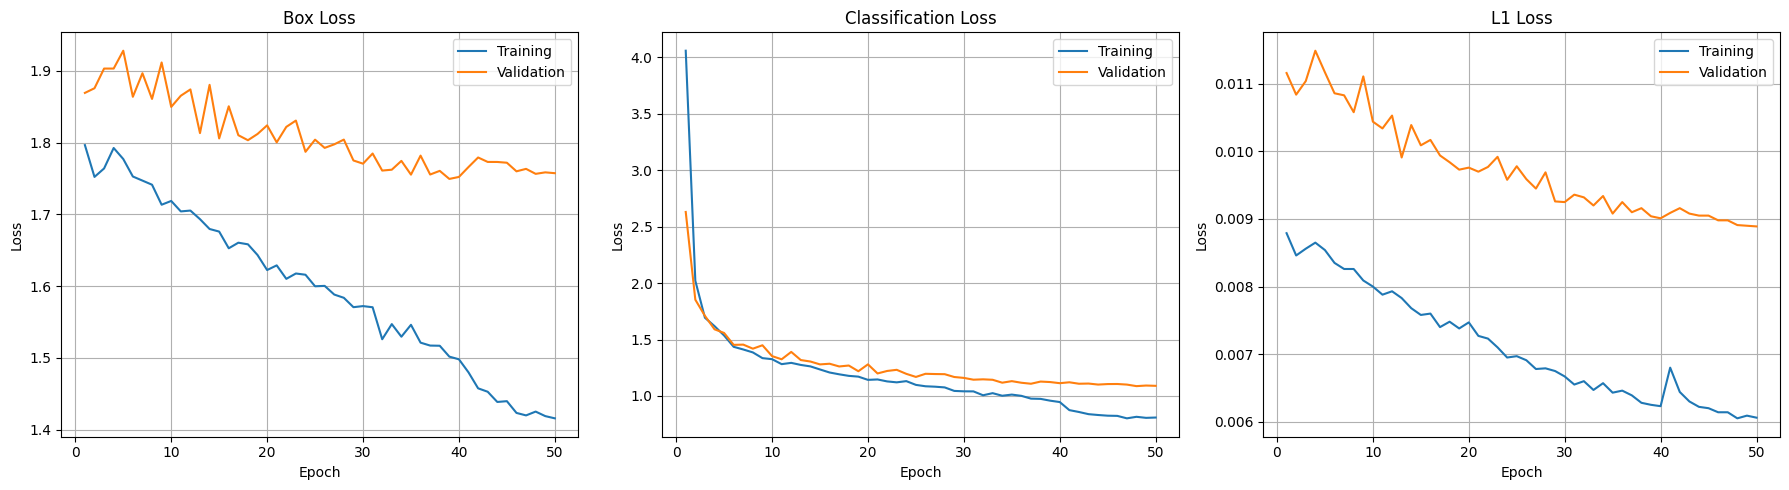

In [ ]:
import matplotlib.pyplot as plt

loss_pairs = [
    ("train/box_loss", "val/box_loss", "Box Loss"),
    ("train/cls_loss", "val/cls_loss", "Classification Loss"),
    ("train/l1_loss", "val/l1_loss", "L1 Loss")
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (train_col, val_col, title) in zip(axes, loss_pairs):

    ax.plot(results_df_yolo26["epoch"], results_df_yolo26[train_col], label="Training")
    ax.plot(results_df_yolo26["epoch"], results_df_yolo26[val_col], label="Validation")

    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()

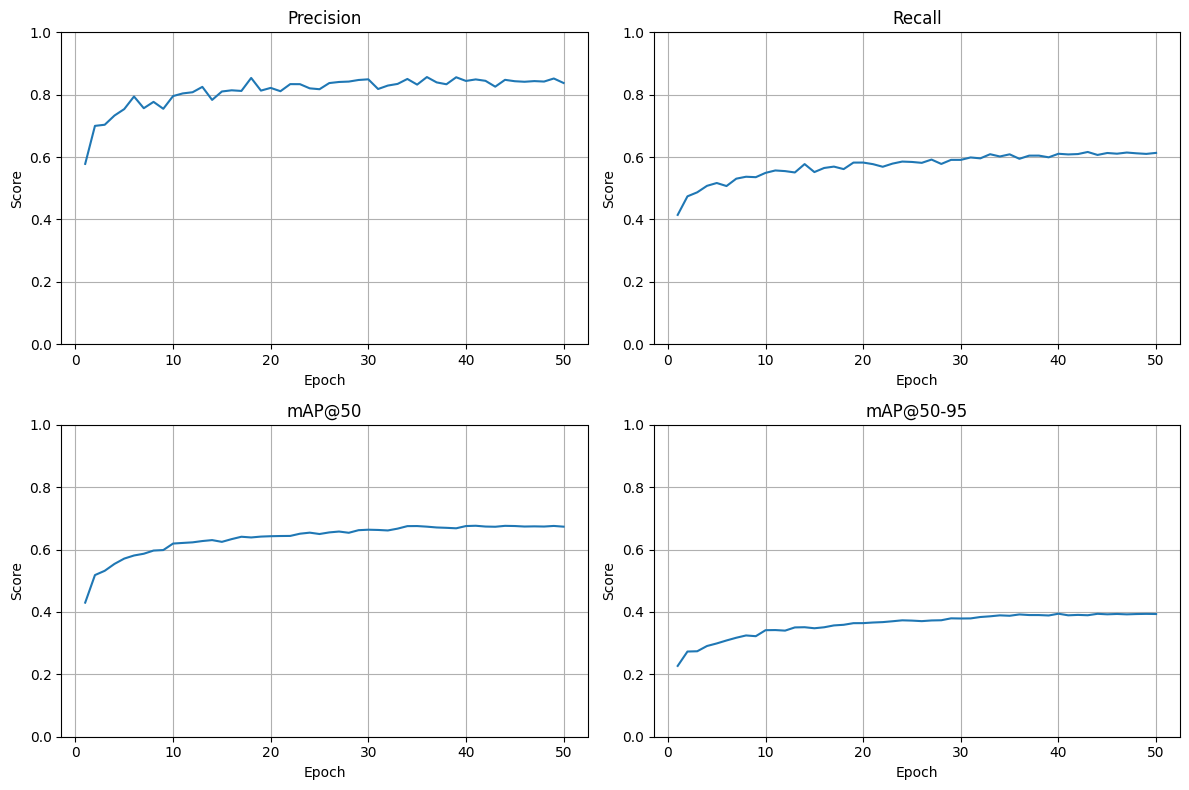

In [ ]:
metric_columns = [
    ("metrics/precision(B)", "Precision"),
    ("metrics/recall(B)", "Recall"),
    ("metrics/mAP50(B)", "mAP@50"),
    ("metrics/mAP50-95(B)", "mAP@50-95")
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, (column, title) in zip(axes.flat, metric_columns):

    ax.plot(results_df_yolo26["epoch"], results_df_yolo26[column])

    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Score")
    ax.set_ylim(0, 1)
    ax.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
import random
import matplotlib.pyplot as plt
from ultralytics import YOLO

model_yolo26 = YOLO(
    "/content/drive/MyDrive/PPE/runs/yolo26n_ppe/weights/best.pt"
)

validation_images = list(
    (processed_path / "valid" / "images").glob("*")
)

random.seed(42)
sample_images = random.sample(validation_images, 6)

predictions_yolo26 = model_yolo26.predict(
    source=[str(image) for image in sample_images],
    imgsz=640,
    conf=0.25,
    device=0,
    verbose=False
)

fig, axes = plt.subplots(2, 3, figsize=(18, 12))

for ax, result in zip(axes.flat, predictions_yolo26):
    annotated_image = result.plot()
    annotated_image = annotated_image[:, :, ::-1]

    ax.imshow(annotated_image)
    ax.set_title(result.path.split("/")[-1])
    ax.axis("off")

plt.tight_layout()
plt.show()

Output hidden; open in https://colab.research.google.com to view.

# YOLO26 Nano — Training and Evaluation Report

## 1. Model Configuration

| Parameter | Configuration |
|---|---|
| Architecture | YOLO26 |
| Variant | Nano |
| Pretrained checkpoint | yolo26n.pt |
| Image size | 640 × 640 |
| Maximum epochs | 50 |
| Batch size | 16 |
| Optimizer | Auto |
| Early stopping patience | 10 |
| Random seed | 42 |
| Hardware | NVIDIA Tesla T4 |

## 2. Training Results

- Epochs completed: 50
- Training duration: 1.166 hours
- Best validation epoch: 40
- Training stopped through early stopping.
- Best checkpoint: best.pt
- Final checkpoint: last.pt

## 3. Validation Performance

| Metric | Result |
|---|---:|
| Precision | 0.846 |
| Recall | 0.610 |
| mAP@50 | 0.676 |
| mAP@50–95 | 0.394 |

## 4. Training Behaviour

Training losses decreased throughout the experiment.

Validation losses initially decreased but gradually plateaued. The training-validation gap remained noticeable, suggesting possible mild overfitting.

Validation performance reached its best recorded result at epoch 40. No subsequent improvement occurred within the early-stopping patience period.

## 5. Visual Prediction Analysis

Six validation images were inspected.

Observations:
- The model detected people across several different scenes.
- Some predictions had relatively low confidence.
- Overlapping bounding boxes were observed.
- PPE classification was inconsistent.
- Small and distant objects remained challenging.
- Scenes containing only excluded object categories did not necessarily produce target-class detections.

## 6. Strengths

- Achieved the highest overall precision and mAP scores among the three experiments.
- Demonstrated reasonable person detection.
- Used fewer parameters than YOLOv8 and YOLO11 Nano.
- Successfully completed training with early stopping.
- Produced saved model checkpoints and experiment results.

## 7. Limitations

- Recall remained relatively low.
- NO-Hardhat detection was particularly weak.
- Bounding-box localization needs improvement.
- Overlapping predictions affected visual interpretation.
- Generalization across different scene types remains a concern.

## 8. Conclusion

YOLO26 Nano achieved the strongest overall validation metrics among the three architectures, although its advantage was small.

Its visual predictions also revealed challenges involving overlapping boxes, small objects and inconsistent PPE classification.

The trained checkpoint is retained for future inference and comparison.

In [ ]:
model_comparison = pd.DataFrame({
    "Model": ["YOLOv8", "YOLO11", "YOLO26"],
    "Precision": [0.827, 0.839, 0.846],
    "Recall": [0.611, 0.608, 0.610],
    "mAP50": [0.673, 0.672, 0.676],
    "mAP50-95": [0.390, 0.389, 0.394],
    "Parameters (M)": [3.13, 2.598, 2.391],
    "Training Time (hours)": [0.847, 1.079, 1.166]
})

model_comparison

,Model,Precision,Recall,mAP50,mAP50-95,Parameters (M),Training Time (hours)
0,YOLOv8,0.827,0.611,0.673,0.390,3.130,0.847
1,YOLO11,0.839,0.608,0.672,0.389,2.598,1.079
2,YOLO26,0.846,0.610,0.676,0.394,2.391,1.166


In [ ]:
from ultralytics import YOLO

model_paths = {
    "YOLOv8": "/content/drive/MyDrive/PPE/runs/yolov8n_ppe/weights/best.pt",
    "YOLO11": "/content/drive/MyDrive/PPE/runs/yolo11n_ppe/weights/best.pt",
    "YOLO26": "/content/drive/MyDrive/PPE/runs/yolo26n_ppe/weights/best.pt"
}

for model_name, model_path in model_paths.items():

    model = YOLO(model_path)

    metrics = model.val(
        data="/content/drive/MyDrive/PPE/processed/data.yaml",
        split="val",
        device=0,
        verbose=False
    )

    print(f"\n{model_name}")
    print(metrics.box.maps)

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,134,165 parameters, 0 gradients, 8.6 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.5±0.1 ms, read: 0.2±0.1 MB/s, size: 97.5 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/drive/MyDrive/PPE/processed/valid/labels.cache... 641 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 641/641 86.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 41/41 2.7it/s 15.4s
                   all        641       5268      0.827      0.611      0.674      0.389
Speed: 1.1ms preprocess, 3.4ms inference, 0.0ms loss, 2.5ms postprocess per image
Results saved to /content/runs/detect/val

YOLOv8
[    0.46482     0.36188     0.29342     0.27768     0.34352     0.50871     0.47569]
Ultralytics 8.4

In [ ]:
from ultralytics import YOLO

model_paths = {
    "YOLOv8": "/content/drive/MyDrive/PPE/runs/yolov8n_ppe/weights/best.pt",
    "YOLO11": "/content/drive/MyDrive/PPE/runs/yolo11n_ppe/weights/best.pt",
    "YOLO26": "/content/drive/MyDrive/PPE/runs/yolo26n_ppe/weights/best.pt"
}

test_results = {}

for model_name, model_path in model_paths.items():

    print(f"\nEvaluating {model_name}...")

    model = YOLO(model_path)

    metrics = model.val(
        data="/content/drive/MyDrive/PPE/processed/data.yaml",
        split="test",
        imgsz=640,
        batch=16,
        device=0,
        verbose=False
    )

    test_results[model_name] = {
        "Precision": metrics.box.mp,
        "Recall": metrics.box.mr,
        "mAP50": metrics.box.map50,
        "mAP50-95": metrics.box.map
    }

    del model

test_comparison = pd.DataFrame(test_results).T

print("\nFINAL TEST SET COMPARISON")
display(test_comparison)


Evaluating YOLOv8...
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,134,165 parameters, 0 gradients, 8.6 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.6±0.2 ms, read: 0.3±0.2 MB/s, size: 133.0 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/drive/MyDrive/PPE/processed/test/labels... 643 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 643/643 2.7it/s 3:57
val: New cache created: /content/drive/MyDrive/PPE/processed/test/labels.cache
WARNING ⚠️ Dataset images contain up to 456 objects (test=456), but max_det=300. This mismatch can cap recall and produce invalid validation metrics. Raising it may increase validation cost but cannot increase model or export capacity, which may cap recall. Setting max_det=456 to match the observed maximum.
                 Class     Images  Instances    

,Precision,Recall,mAP50,mAP50-95
YOLOv8,0.817181,0.605034,0.659850,0.386338
YOLO11,0.835490,0.596151,0.660252,0.391028
YOLO26,0.840056,0.595066,0.657262,0.383311


# PPE Object Detection — Model Experimentation and Evaluation

## 1. Project Overview

The objective of this project was to develop a construction-site object detection system capable of identifying seven PPE-related object categories using YOLO architectures.

Three YOLO generations were selected, trained and evaluated to determine the most suitable architecture for the application.

The experiments focused on comparing detection performance, localization accuracy, model complexity and computational requirements.

## 2. Dataset Preparation

### Dataset Source

Construction Hazard Detection Dataset (Roboflow).

- Dataset version: 97
- Original images: 6,689
- Original classes: 11
- Selected classes: 7
- Prepared images: 4,280
- Retained bounding boxes: 34,176

### Selected Classes

| Class ID | Class Name |
|---:|---|
| 0 | Hardhat |
| 1 | Mask |
| 2 | NO-Hardhat |
| 3 | NO-Mask |
| 4 | NO-Safety Vest |
| 5 | Person |
| 6 | Safety Vest |

The original dataset contained empty annotation files and classes outside the project's scope. The prepared dataset excluded images that did not contribute to the selected target classes.

The original dataset was preserved unchanged.

### Dataset Splitting

The prepared dataset was divided into three subsets using multilabel stratification to maintain similar class representation across the splits.

| Split | Images | Percentage |
|---|---:|---:|
| Training | 2,996 | 70% |
| Validation | 641 | 15% |
| Testing | 643 | 15% |
| **Total** | **4,280** | **100%** |

### Dataset Validation

The prepared dataset passed the following checks:

- Every image had a corresponding annotation file.
- No missing image-label pairs.
- No invalid class IDs.
- No malformed annotation rows.
- All bounding-box coordinates were within the valid normalized range.

The dataset was exported using the YOLO annotation format and configured through a `data.yaml` file.

## 3. Experimental Setup

All three architectures were evaluated under the same initial training configuration.

| Parameter | Configuration |
|---|---|
| Framework | Ultralytics |
| Image size | 640 × 640 |
| Maximum epochs | 50 |
| Batch size | 16 |
| Optimizer | Auto |
| Early stopping patience | 10 |
| Random seed | 42 |
| Training device | NVIDIA Tesla T4 |
| Model variant | Nano |

### Models Evaluated

1. YOLOv8 Nano — `yolov8n.pt`
2. YOLO11 Nano — `yolo11n.pt`
3. YOLO26 Nano — `yolo26n.pt`

All models were initialized using pretrained weights and fine-tuned on the prepared PPE dataset.

The same training, validation and test splits were used throughout the experiments.

## 4. Training Results

| Model | Epochs Completed | Training Time | Parameters |
|---|---:|---:|---:|
| YOLOv8 Nano | 50 | 0.847 hours | 3.13M |
| YOLO11 Nano | 50 | 1.079 hours | 2.60M |
| YOLO26 Nano | 50 | 1.166 hours | 2.39M |

YOLO26 stopped improving on the monitored validation fitness after epoch 40 and completed training through early stopping.

### Training Behaviour Analysis

Training and validation losses were examined for all three architectures.

The general observations were:

- Training losses decreased consistently.
- Validation losses initially decreased before gradually plateauing.
- Training-validation gaps remained visible.
- Validation improvements became marginal during later epochs.

These patterns suggest generalization gaps and possible mild overfitting.

YOLOv8 and YOLO11 used Distribution Focal Loss (DFL), while YOLO26 reported L1 loss. Their loss values were therefore not treated as directly interchangeable.

## 5. Validation Performance

The saved checkpoints were evaluated on the validation dataset.

| Metric | YOLOv8 | YOLO11 | YOLO26 |
|---|---:|---:|---:|
| Precision | 0.827 | 0.844 | 0.856 |
| Recall | 0.611 | 0.606 | 0.608 |
| mAP@50 | 0.674 | 0.672 | 0.679 |
| mAP@50–95 | 0.389 | 0.390 | 0.396 |

YOLO26 achieved the strongest overall validation metrics.

However, the differences between the three architectures were relatively small.

## 6. Test Performance

The three saved checkpoints were subsequently evaluated on the held-out test dataset containing 643 images.

| Metric | YOLOv8 | YOLO11 | YOLO26 |
|---|---:|---:|---:|
| Precision | 0.817 | 0.835 | 0.840 |
| Recall | 0.605 | 0.596 | 0.596 |
| mAP@50 | 0.660 | 0.660 | 0.657 |
| mAP@50–95 | 0.386 | **0.391** | 0.383 |

### Interpretation

**YOLOv8 Nano**
- Achieved the highest recall.
- Had the shortest training time.
- Demonstrated competitive overall detection performance.

**YOLO11 Nano**
- Achieved the highest test mAP@50–95.
- Matched YOLOv8's mAP@50.
- Demonstrated a good balance between precision, recall and localization performance.

**YOLO26 Nano**
- Achieved the highest precision.
- Had the lowest parameter count.
- Did not maintain its validation advantage on the test dataset.

## 7. Class-Specific Performance

Class-specific mAP@50–95 was also examined on the validation dataset.

| Class | YOLOv8 | YOLO11 | YOLO26 |
|---|---:|---:|---:|
| Hardhat | 0.465 | 0.474 | 0.485 |
| Mask | 0.362 | 0.349 | 0.355 |
| NO-Hardhat | 0.293 | 0.287 | 0.285 |
| NO-Mask | 0.278 | 0.294 | 0.281 |
| NO-Safety Vest | 0.344 | 0.335 | 0.347 |
| Person | 0.509 | 0.508 | 0.527 |
| Safety Vest | 0.476 | 0.480 | 0.492 |

The results showed that no architecture dominated every class.

YOLO26 performed best on four classes, YOLOv8 on two, and YOLO11 on one.

This demonstrated the importance of examining class-specific performance rather than relying exclusively on overall metrics.

## 8. Visual Prediction Analysis

Six validation images were inspected for each architecture using the saved best checkpoints.

The visual investigation revealed:

- Reasonable person detection across different scenes.
- Inconsistent detection of some PPE categories.
- Overlapping bounding boxes in crowded scenes.
- Challenges detecting small and distant objects.
- Variations in prediction confidence.
- Differences in detection behaviour across scene types.

The visual inspection complemented the numerical evaluation and helped identify practical limitations that aggregate metrics could not fully explain.

## 9. Model Selection

### Selected Architecture: YOLO11 Nano

YOLO11 Nano was selected based primarily on its test mAP@50–95 of 0.391, the highest among the three evaluated architectures.

The selection rationale was:

1. It achieved the highest test mAP@50–95.
2. It achieved the highest test mAP@50 jointly with YOLOv8.
3. It maintained competitive precision and recall.
4. Its performance was relatively balanced across the evaluated detection metrics.

Although YOLO26 achieved the highest precision, it recorded a lower test mAP@50–95.

YOLOv8 achieved the highest recall but had slightly lower localization performance than YOLO11.

The differences between the models were small, so YOLO11 should be considered the selected experimental candidate rather than a conclusively superior architecture.

### Final Model

| Attribute | Selected Configuration |
|---|---|
| Architecture | YOLO11 |
| Variant | Nano |
| Checkpoint | `best.pt` |
| Test precision | 0.835 |
| Test recall | 0.596 |
| Test mAP@50 | 0.660 |
| Test mAP@50–95 | 0.391 |

## 10. Model Artifact Storage

The selected model checkpoint is stored at:

`runs/yolo11n_ppe/weights/best.pt`

The experiment directory also contains training results, validation plots and other generated artifacts.

The `best.pt` checkpoint will be used for subsequent inference and application development.

## 11. Limitations and Future Improvements

The experiments identified several areas for future improvement:

- Relatively low recall across the three architectures.
- Weak detection performance on certain classes.
- Difficulty detecting small and distant objects.
- Overlapping predictions in crowded scenes.
- Generalization gaps between training and validation performance.
- Potential benefits from improved dataset quality, augmentation and hyperparameter optimization.

The current system performs object detection on seven annotated categories. It does not implement person-to-PPE association or individual worker compliance verification.

## 12. Conclusion

Three YOLO Nano architectures were trained and evaluated using a common prepared dataset and experimental configuration.

YOLO26 achieved the strongest overall validation metrics, but YOLO11 achieved the highest test mAP@50–95.

YOLO11 Nano was therefore selected as the model for subsequent application development.

The model experimentation phase is complete. The next stage will focus on building an inference application that supports image and video object detection using the selected checkpoint.

In [13]:
%cd /content/drive/MyDrive/PPE

!git status --short
!du -sh notebooks/
!ls -lh notebooks/
!cat .gitignore

/content/drive/MyDrive/PPE
?? .gitignore
?? models/
?? notebooks/
4.9M	notebooks/
total 4.9M
-rw------- 1 root root 2.3M Nov 20 20:56 'data_inspection_and _training.ipynb'
-rw------- 1 root root 2.7M Nov 22 14:10  model_training.ipynb

# Dataset files
*.zip
*.7z
*.tar
*.tar.gz
PPEGuard_Data/
processed/
datasets/
data/

# Model weights and exported models
*.pt
*.pth
*.onnx
*.engine
*.torchscript

# Training outputs
runs/
wandb/
mlruns/

# Python environments and cache
.venv/
venv/
__pycache__/
*.py[cod]
.pytest_cache/

# Jupyter temporary files
.ipynb_checkpoints/

# Environment variables and secrets
.env
.env.*
!.env.example

# System files
.DS_Store
Thumbs.db

# Model weights and exported models
*.pt
*.pth
*.onnx
*.engine
*.torchscript

# Keep the selected model in GitHub
!models/yolo11n_ppe_best.pt
